# Indoor Location Prediction: Machine Learning Modeling & Benchmarking
**Project 9 · CSAI Student Project · Phase 1: Machine Learning Evaluation**

## 1. Overview and Modeling Objectives
This notebook implements the multi-task indoor location benchmarking pipeline:
1. **Multi-Class Classification**:
   - **Building Identification** (Buildings 0, 1, 2)
   - **Floor Identification** (Floors 0 to 4)
2. **Spatial Coordinate Regression**:
   - Predicting continuous `LATITUDE` and `LONGITUDE` in meters.
3. **Core Evaluation Metrics**:
   - **Building Accuracy** (%)
   - **Floor Accuracy** (%)
   - **Mean and Median Euclidean Distance Error (in meters)**:
     $$\text{Error} = \sqrt{(\text{Lat}_{\text{true}} - \text{Lat}_{\text{pred}})^2 + (\text{Lon}_{\text{true}} - \text{Lon}_{\text{pred}})^2}$$
   - **Hierarchical Error Breakdown**: Evaluating coordinate error when the Building and Floor are correctly classified versus misclassified.
4. **Candidate Estimator Benchmarking**:
   - **Baseline 1**: K-Nearest Neighbors (KNN with spatial distance metric)
   - **Baseline 2**: Random Forest Classifier & Regressor Ensembles
   - **Baseline 3**: Gradient Boosted Decision Trees (XGBoost)


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print('Imported evaluation & modeling packages.')


Imported evaluation & modeling packages.


## 2. Load Processed Data
Ingesting the serialized clean feature matrices generated in `02_preprocessing.ipynb`.


In [2]:
data_path = '../Datasets/processed/preprocessed_wifi_data.joblib'
if not os.path.exists(data_path):
    data_path = 'Datasets/processed/preprocessed_wifi_data.joblib'

data = joblib.load(data_path)

X_train = data['X_train']
X_val = data['X_val']

y_train_bldg = data['y_train_bldg']
y_val_bldg = data['y_val_bldg']

y_train_floor = data['y_train_floor']
y_val_floor = data['y_val_floor']

y_train_coords = data['y_train_coords']
y_val_coords = data['y_val_coords']

print(f'Loaded X_train: {X_train.shape}, X_val: {X_val.shape}')


Loaded X_train: (19861, 469), X_val: (1111, 469)


## 3. Helper Functions for Evaluation & Euclidean Error Calculation
Calculates standard classification metrics and spatial Euclidean distance errors in meters.


In [3]:
def compute_euclidean_error(y_true, y_pred):
    '''
    Computes Euclidean positioning error in meters between true and predicted (Lat, Lon).
    '''
    lat_diff = y_true[:, 0] - y_pred[:, 0]
    lon_diff = y_true[:, 1] - y_pred[:, 1]
    return np.sqrt(lat_diff**2 + lon_diff**2)

def evaluate_location_system(name, bldg_pred, floor_pred, coords_pred, y_val_b, y_val_f, y_val_c):
    bldg_acc = accuracy_score(y_val_b, bldg_pred) * 100
    floor_acc = accuracy_score(y_val_f, floor_pred) * 100
    
    errors = compute_euclidean_error(y_val_c, coords_pred)
    mean_err = np.mean(errors)
    median_err = np.median(errors)
    p75_err = np.percentile(errors, 75)
    p90_err = np.percentile(errors, 90)
    
    # Combined Success Rate (Correct Building AND Correct Floor)
    perfect_symbolic = np.mean((bldg_pred == y_val_b) & (floor_pred == y_val_f)) * 100
    
    res = {
        'Model': name,
        'Building Accuracy (%)': round(bldg_acc, 2),
        'Floor Accuracy (%)': round(floor_acc, 2),
        'Bldg & Floor Match (%)': round(perfect_symbolic, 2),
        'Mean Coord Error (m)': round(mean_err, 2),
        'Median Coord Error (m)': round(median_err, 2),
        '75th %ile Error (m)': round(p75_err, 2),
        '90th %ile Error (m)': round(p90_err, 2)
    }
    return res, errors


## 4. Model 1: K-Nearest Neighbors (KNN Benchmark)
In Wi-Fi fingerprinting, matching a live RSSI vector to the $k$ closest historical calibration points in signal space provides an intuitive, non-parametric baseline.


In [4]:
print('Training K-Nearest Neighbors Models...')

# Building & Floor
knn_bldg = KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1)
knn_bldg.fit(X_train, y_train_bldg)
knn_bldg_pred = knn_bldg.predict(X_val)

knn_floor = KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1)
knn_floor.fit(X_train, y_train_floor)
knn_floor_pred = knn_floor.predict(X_val)

# Coordinates
knn_coords = KNeighborsRegressor(n_neighbors=5, metric='euclidean', n_jobs=-1)
knn_coords.fit(X_train, y_train_coords)
knn_coords_pred = knn_coords.predict(X_val)

knn_res, knn_errors = evaluate_location_system(
    'K-Nearest Neighbors (k=5)', 
    knn_bldg_pred, knn_floor_pred, knn_coords_pred, 
    y_val_bldg, y_val_floor, y_val_coords
)
print('KNN Benchmark Results:')
print(pd.Series(knn_res))


Training K-Nearest Neighbors Models...


KNN Benchmark Results:
Model                     K-Nearest Neighbors (k=5)
Building Accuracy (%)                         98.11
Floor Accuracy (%)                            74.71
Bldg & Floor Match (%)                        74.17
Mean Coord Error (m)                          15.88
Median Coord Error (m)                         8.96
75th %ile Error (m)                           17.12
90th %ile Error (m)                           33.63
dtype: object


## 5. Model 2: Random Forest Ensemble
Ensemble decision trees can partition the non-linear RSSI feature space effectively and are resilient to feature noise.


In [5]:
print('Training Random Forest Ensemble Models...')

rf_bldg = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=42, n_jobs=-1)
rf_bldg.fit(X_train, y_train_bldg)
rf_bldg_pred = rf_bldg.predict(X_val)

rf_floor = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=42, n_jobs=-1)
rf_floor.fit(X_train, y_train_floor)
rf_floor_pred = rf_floor.predict(X_val)

rf_coords = RandomForestRegressor(n_estimators=100, max_depth=25, random_state=42, n_jobs=-1)
rf_coords.fit(X_train, y_train_coords)
rf_coords_pred = rf_coords.predict(X_val)

rf_res, rf_errors = evaluate_location_system(
    'Random Forest (n=100)', 
    rf_bldg_pred, rf_floor_pred, rf_coords_pred, 
    y_val_bldg, y_val_floor, y_val_coords
)
print('Random Forest Results:')
print(pd.Series(rf_res))


Training Random Forest Ensemble Models...


Random Forest Results:
Model                     Random Forest (n=100)
Building Accuracy (%)                     99.82
Floor Accuracy (%)                        87.85
Bldg & Floor Match (%)                    87.76
Mean Coord Error (m)                      16.48
Median Coord Error (m)                     8.76
75th %ile Error (m)                       19.37
90th %ile Error (m)                       39.06
dtype: object


## 6. Model 3: XGBoost (Gradient Boosted Decision Trees)
Gradient boosting iteratively minimizes residual errors across tabular features.


In [6]:
print('Training XGBoost Models...')

xgb_bldg = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_bldg.fit(X_train, y_train_bldg)
xgb_bldg_pred = xgb_bldg.predict(X_val)

xgb_floor = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_floor.fit(X_train, y_train_floor)
xgb_floor_pred = xgb_floor.predict(X_val)

xgb_coords = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_coords.fit(X_train, y_train_coords)
xgb_coords_pred = xgb_coords.predict(X_val)

xgb_res, xgb_errors = evaluate_location_system(
    'XGBoost (n=100)', 
    xgb_bldg_pred, xgb_floor_pred, xgb_coords_pred, 
    y_val_bldg, y_val_floor, y_val_coords
)
print('XGBoost Results:')
print(pd.Series(xgb_res))


Training XGBoost Models...


XGBoost Results:
Model                     XGBoost (n=100)
Building Accuracy (%)               99.55
Floor Accuracy (%)                  89.47
Bldg & Floor Match (%)               89.2
Mean Coord Error (m)                20.25
Median Coord Error (m)              13.56
75th %ile Error (m)                 23.25
90th %ile Error (m)                 42.64
dtype: object


## 7. Model Comparison & Leaderboard
We consolidate the performance metrics of all candidate architectures.


In [7]:
comparison_df = pd.DataFrame([knn_res, rf_res, xgb_res])
print('=== MODEL COMPARISON LEADERBOARD ===')
display(comparison_df)


=== MODEL COMPARISON LEADERBOARD ===


,Model,Building Accuracy (%),Floor Accuracy (%),Bldg & Floor Match (%),Mean Coord Error (m),Median Coord Error (m),75th %ile Error (m),90th %ile Error (m)
0,K-Nearest Neighbors (k=5),98.11,74.71,74.17,15.88,8.96,17.12,33.63
1,Random Forest (n=100),99.82,87.85,87.76,16.48,8.76,19.37,39.06
2,XGBoost (n=100),99.55,89.47,89.20,20.25,13.56,23.25,42.64


## 8. Error Distribution & Empirical Cumulative Distribution Functions (ECDF)
Plotting the cumulative distribution of Euclidean distance errors provides the standard spatial performance curve in indoor positioning literature.


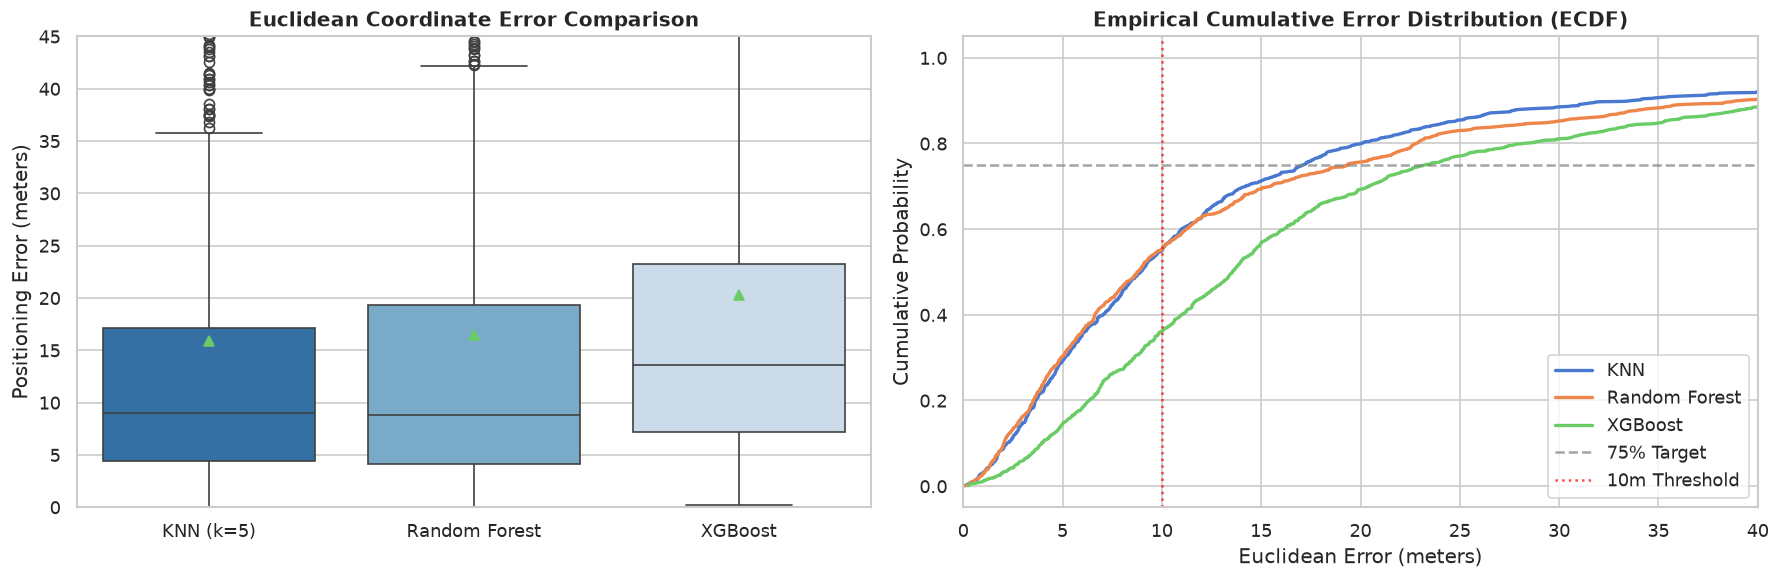

In [8]:
fig_dir = '../figures' if os.path.exists('../figures') else 'figures'
os.makedirs(fig_dir, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Error Distribution Boxplot
error_data = pd.DataFrame({
    'KNN (k=5)': knn_errors,
    'Random Forest': rf_errors,
    'XGBoost': xgb_errors
})
sns.boxplot(data=error_data, ax=axes[0], palette='Blues_r', showmeans=True)
axes[0].set_title('Euclidean Coordinate Error Comparison', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Positioning Error (meters)')
axes[0].set_ylim(0, 45)

# ECDF curve
for col, err in [('KNN', knn_errors), ('Random Forest', rf_errors), ('XGBoost', xgb_errors)]:
    sorted_err = np.sort(err)
    ecdf = np.arange(1, len(sorted_err) + 1) / len(sorted_err)
    axes[1].plot(sorted_err, ecdf, label=col, linewidth=2)

axes[1].axhline(0.75, color='gray', linestyle='--', alpha=0.7, label='75% Target')
axes[1].axvline(10.0, color='red', linestyle=':', alpha=0.7, label='10m Threshold')
axes[1].set_xlim(0, 40)
axes[1].set_title('Empirical Cumulative Error Distribution (ECDF)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Euclidean Error (meters)')
axes[1].set_ylabel('Cumulative Probability')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{fig_dir}/model_error_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


## 9. Floor Classification Confusion Matrix (Champion Model)
Examining whether floor prediction errors occur primarily in adjacent floors (e.g. Floor 2 confused for Floor 1 or 3 due to vertical signal penetration).


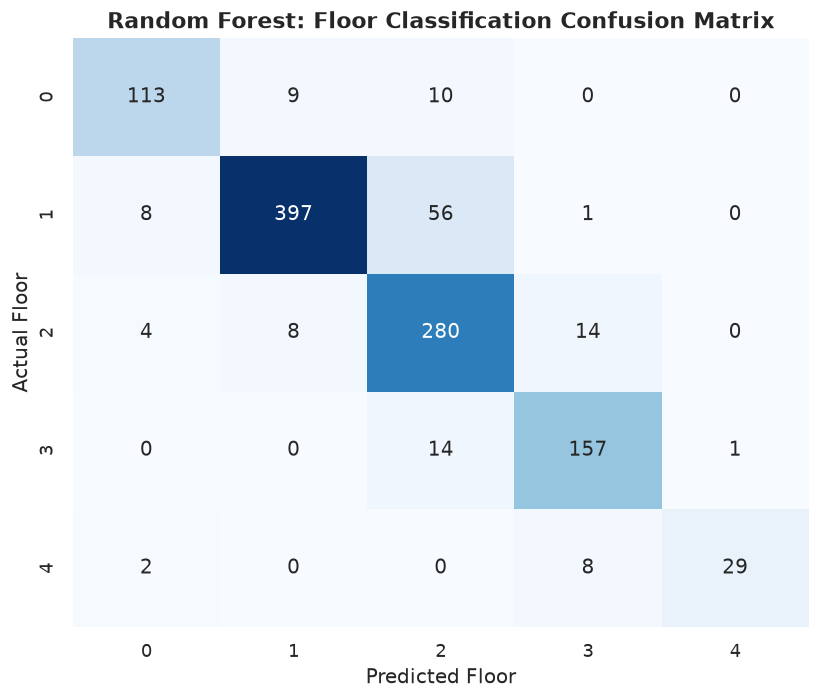

Classification Report for Floor Prediction:
              precision    recall  f1-score   support

           0       0.89      0.86      0.87       132
           1       0.96      0.86      0.91       462
           2       0.78      0.92      0.84       306
           3       0.87      0.91      0.89       172
           4       0.97      0.74      0.84        39

    accuracy                           0.88      1111
   macro avg       0.89      0.86      0.87      1111
weighted avg       0.89      0.88      0.88      1111



In [9]:
cm = confusion_matrix(y_val_floor, rf_floor_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Random Forest: Floor Classification Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Floor')
plt.ylabel('Actual Floor')
plt.tight_layout()
plt.savefig(f'{fig_dir}/floor_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

print('Classification Report for Floor Prediction:')
print(classification_report(y_val_floor, rf_floor_pred))


## 10. Spatial Error Map
Visualizes where large coordinate prediction errors occur across the campus building footprint.


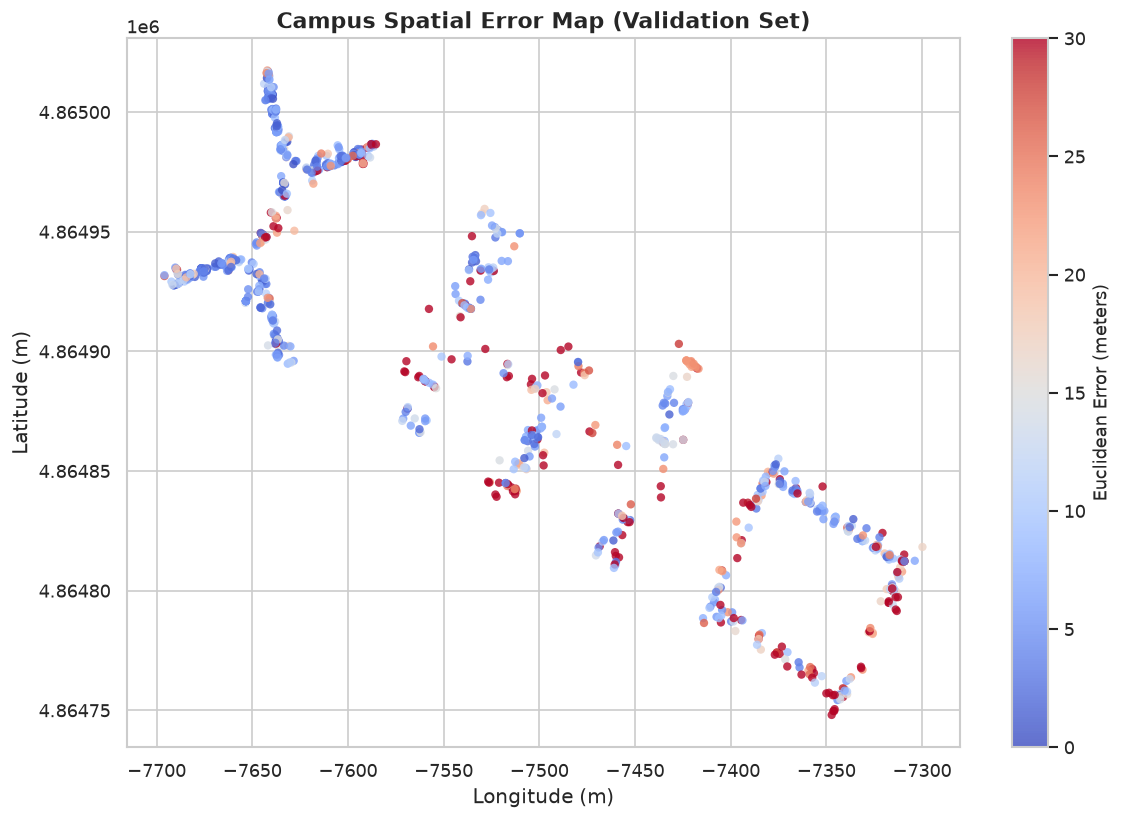

In [10]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    y_val_coords[:, 1], y_val_coords[:, 0], 
    c=rf_errors, cmap='coolwarm', s=25, alpha=0.8, edgecolor='none', vmin=0, vmax=30
)
cbar = plt.colorbar(scatter)
cbar.set_label('Euclidean Error (meters)', fontsize=11)
plt.title('Campus Spatial Error Map (Validation Set)', fontsize=13, fontweight='bold')
plt.xlabel('Longitude (m)')
plt.ylabel('Latitude (m)')
plt.tight_layout()
plt.savefig(f'{fig_dir}/spatial_error_map.png', dpi=200, bbox_inches='tight')
plt.show()


## 11. Hierarchical Error Breakdown
Analyzes the physical dependency between structural classifications and coordinate regressions:
- Coordinate error when Building and Floor are BOTH correctly identified.
- Coordinate error when Floor is misclassified.


In [11]:
correct_both = (rf_bldg_pred == y_val_bldg) & (rf_floor_pred == y_val_floor)
hierarchical_analysis = pd.DataFrame([
    {
        'Subset': 'Both Building & Floor Correct',
        'Sample Count': int(np.sum(correct_both)),
        'Percentage (%)': round(np.mean(correct_both) * 100, 2),
        'Mean Coord Error (m)': round(float(np.mean(rf_errors[correct_both])), 2),
        'Median Coord Error (m)': round(float(np.median(rf_errors[correct_both])), 2)
    },
    {
        'Subset': 'Floor Misclassified',
        'Sample Count': int(np.sum(~correct_both)),
        'Percentage (%)': round(np.mean(~correct_both) * 100, 2),
        'Mean Coord Error (m)': round(float(np.mean(rf_errors[~correct_both])), 2),
        'Median Coord Error (m)': round(float(np.median(rf_errors[~correct_both])), 2)
    }
])
print('=== HIERARCHICAL ERROR BREAKDOWN ===')
display(hierarchical_analysis)


=== HIERARCHICAL ERROR BREAKDOWN ===


,Subset,Sample Count,Percentage (%),Mean Coord Error (m),Median Coord Error (m)
0,Both Building & Floor Correct,975,87.76,14.48,8.04
1,Floor Misclassified,136,12.24,30.85,19.55


## 12. Save Champion Pipeline Assets
Serializes the trained champion models for downstream deployment or interactive evaluation.


In [12]:
models_dir = '../Reports' if os.path.exists('../Reports') else 'Reports'
os.makedirs(models_dir, exist_ok=True)

champion_assets = {
    'model_name': 'Random Forest Ensemble',
    'bldg_model': rf_bldg,
    'floor_model': rf_floor,
    'coords_model': rf_coords,
    'validation_metrics': rf_res,
    'comparison_table': comparison_df.to_dict(orient='records'),
    'hierarchical_breakdown': hierarchical_analysis.to_dict(orient='records')
}

joblib.dump(champion_assets, os.path.join(models_dir, 'champion_models.joblib'))
print('Champion model assets serialized successfully.')


Champion model assets serialized successfully.
